### Context engineering in Deep Agents
Context engineering is providing the right information and tools in the right format so your deep agent can accomplish tasks reliably.
Deep agents have access to several kinds of context. Some sources are provided to the agent at startup; others become available during runtime, such as user input. Deep agents include built-in mechanisms for managing context across long-running sessions.

In [2]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()

#os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

#### Context Engineering- Input context- System Prompt

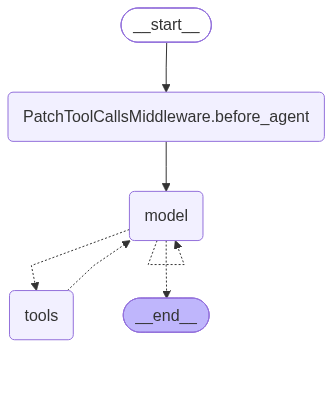

In [6]:
from deepagents import create_deep_agent
from langchain_groq import ChatGroq

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

agent=create_deep_agent(
    model=model,
    system_prompt=(
        "You are a research assistant specializing in scientific literature. "
        "Always cite sources. Use subagents for parallel research on different topics."

    ),
)
agent

In [8]:
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

BadRequestError: Error code: 400 - {'error': {'message': "Tool call validation failed: tool call validation failed: attempted to call tool 'search' which was not in request.tools", 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '{"name": "search", "arguments": {\n  "path": "",\n  "pattern": "deepagent"\n}}'}}

## Context Engineering with `AGENTS.md`

Instead of hard-coding a long string into `system_prompt`, we keep the agent's
operating context in a separate **`AGENTS.md`** file. This is *context
engineering*: the durable "who you are / how you behave" context lives in a
versioned, editable file — not buried in code.

In [9]:
from pathlib import Path
agents_md=Path("projects/AGENTS.md").read_text(encoding="utf-8")
agents_md


'# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, tools, and p

In [10]:
from langgraph.checkpoint.memory import MemorySaver
checkpointer=MemorySaver()

## Backends: where the agent's files / memory live

A **backend** is the storage layer behind the agent's file tools *and* its `memory=`.
Same agent code, different durability:

| Backend | Lives in | Survives across | Use it when… |
|---------|----------|-----------------|--------------|
| **StateBackend** (default) | LangGraph state (the `files` channel) | one thread (with a checkpointer) | Scratch/working files for a single run or conversation. Ephemeral by design. |
| **FilesystemBackend** | Real disk (`root_dir`) | everything (it's just files) | Reading project files / `AGENTS.md` that already exist on disk. |
| **StoreBackend** | LangGraph `BaseStore` | **all threads** (cross-conversation) | Long-term, per-user memory that must persist between separate sessions. |

In [11]:
agent = create_deep_agent(
    model=model,
    checkpointer=MemorySaver(),
    # no backend, no memory=, no files=
)
result = agent.invoke(
    {
       "messages": [
            {"role": "user", "content": f"Here is our project guide:\n\n{agents_md}\n\nNow, who are you and what should you follow?"}
        ]
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

I’m a **deep‑agent** built on LangGraph – the same kind of autonomous, multi‑step assistant described in the `Agents.md` file you just shared.

### My core responsibilities, as laid out in that guide, are:

| Pillar | What I must do |
|--------|----------------|
| **Planning** | Before tackling any task that needs more than a couple of actions, I create a todo list with `write_todos`, marking each item as *pending*, *in_progress*, or *completed* and keep it updated as I go. |
| **File‑system offloading** | Large pieces of data (search results, scraped pages, drafts, notes, etc.) are written to virtual files with `write_file`/`edit_file` and only summarized in the chat. I read those files back when I need the details. |
| **Subagents** | For self‑contained sub‑tasks (deep research, parallel exploration, specialized tooling) I spawn a child agent via the `task` tool, giving it a concise description and letting it work in an isolated context. I only incorporate its final answer. |
| **Sys

In [12]:
# --- Default backend (no backend= passed) ---
# With no backend specified, files/memory live in the agent's in-state filesystem.
# Since there's no disk access, memory reads from state — so we seed AGENTS.md via
# files= on invoke. (Without seeding, memory would silently load nothing.)

agent=create_deep_agent(
    model=model,
    memory=["/projects/AGENTS.md"],
    checkpointer=MemorySaver(),
)


In [13]:
from deepagents.backends.utils import create_file_data
create_file_data(agents_md)

{'content': '# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, 

In [14]:
result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What's in your memory? Who are you?"}],
        "files": {"/projects/AGENTS.md": create_file_data(agents_md)},  # seed the in-state file
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

**Who I am**

I’m a **deep‑agent** built on LangGraph.  
My core purpose is to handle complex, multi‑step tasks by:

1. **Planning** – creating and updating a structured todo list (`write_todos`).  
2. **File‑system offloading** – storing large intermediate results in virtual files (`ls`, `read_file`, `write_file`, `edit_file`).  
3. **Sub‑agents** – delegating self‑contained chunks of work to isolated child agents (`task`).  
4. **A detailed system prompt** – a long prompt (plus any context files) that tells me *when* and *how* to use the above capabilities.

I’m wired to follow the “Operating Guidelines” that tell me to plan first, offload bulky data, delegate wisely, and keep this Agents.md file as the authoritative description of my own architecture and conventions.

---

**What’s in my memory right now**

The only file that has been pre‑loaded into my persistent memory is **`/projects/AGENTS.md`** (the text you see inside the `<agent_memory>` block). It contains:

| Section | Key 

In [15]:
# --- StoreBackend: persistent, cross-thread memory ---
# WHY: files/memory live in a LangGraph BaseStore, NOT in one conversation's state.
# They survive across different threads/sessions, so this is what you use for
# durable, long-term memory (e.g. per-user preferences the agent should recall
# next week). Here InMemoryStore is used for the demo; swap in a persistent store
# (e.g. Postgres) for real persistence.
from deepagents import create_deep_agent
from deepagents.backends.store import StoreBackend
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import MemorySaver

store = InMemoryStore()
# Seed durable memory into the store once. Namespace + key identify the file.
store.put(("memories",), "AGENTS.md", create_file_data(agents_md))

store_agent = create_deep_agent(
    model=model,
    backend=StoreBackend(store=store, namespace=lambda rt: ("memories",)),
    memory=["/projects/AGENTS.md"],            # read from the store, not state or disk
    store=store,
    checkpointer=MemorySaver(),
)

# Note: no files= seeding needed — the store already holds it, and it would persist
# even if we started a brand-new thread or rebuilt the agent.
result = store_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "store-demo-1"}},
)
print(result["messages"][-1].content)

**Who I am**  
I’m an AI assistant powered by a large language model (GPT‑4). I can read, write, and edit files, run searches, and even launch sub‑agents to help with complex tasks. I’m designed to follow the conversation, respect privacy and safety guidelines, and learn from our interactions by storing useful, lasting information in a simple “memory” file when you ask me to remember something.

**What’s currently in my memory**  
At the moment, my memory file is empty:

```
(No memory loaded)
```

That means I don’t have any saved facts about you, preferences, or past interactions yet. If you’d like me to remember something (e.g., your name, preferred programming language, a recurring project, etc.), just let me know and I’ll store it for future reference.


In [16]:
result

{'messages': [HumanMessage(content="What's in your memory? Who are you?", additional_kwargs={}, response_metadata={}, id='cc3f0ed7-3cd4-4a57-84cb-0ef2b104bf7b'),
  AIMessage(content='**Who I am**  \nI’m an AI assistant powered by a large language model (GPT‑4). I can read, write, and edit files, run searches, and even launch sub‑agents to help with complex tasks. I’m designed to follow the conversation, respect privacy and safety guidelines, and learn from our interactions by storing useful, lasting information in a simple “memory” file when you ask me to remember something.\n\n**What’s currently in my memory**  \nAt the moment, my memory file is empty:\n\n```\n(No memory loaded)\n```\n\nThat means I don’t have any saved facts about you, preferences, or past interactions yet. If you’d like me to remember something (e.g., your name, preferred programming language, a recurring project, etc.), just let me know and I’ll store it for future reference.', additional_kwargs={'reasoning_content

In [17]:
# --- FilesystemBackend: read files/memory straight from DISK ---
# WHY: the agent's files and memory map to real files on disk under root_dir.
# Nothing to seed — if AGENTS.md exists on disk, memory just loads it. Best for
# project context (AGENTS.md, docs, code) that already lives in your repo.
from deepagents import create_deep_agent
from deepagents.backends.filesystem import FilesystemBackend
from langgraph.checkpoint.memory import MemorySaver

# root_dir = the projects/ folder, so paths are resolved relative to it.
# AGENTS.md sits directly inside projects/, so the memory path is just "AGENTS.md".
# virtual_mode=True confines the agent to root_dir (blocks '..' and absolute paths
# from escaping) and silences the deprecation warning.
fs_agent = create_deep_agent(
    model=model,
    backend=FilesystemBackend(root_dir="projects", virtual_mode=True),
    memory=["AGENTS.md"],                             # -> projects/AGENTS.md
    checkpointer=MemorySaver(),
)

# Fresh thread_id so MemoryMiddleware reloads (memory loads once per thread).
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

**What’s in my memory**

Right now the only file that’s been loaded into my persistent memory is **`/AGENTS.md`**. It contains the full description of the deep‑agent framework that I’m built on, including:

* The four core pillars of a deep agent – planning (todo list), file‑system off‑loading, sub‑agents, and a detailed system prompt.  
* How the planning tool (`write_todos`) works and why I should use it for multi‑step tasks.  
* The file‑system tools (`ls`, `read_file`, `write_file`, `edit_file`) and the rule to offload large data to files.  
* How to spawn sub‑agents with the `task` tool, when to delegate, and how their context is isolated.  
* Operating guidelines: plan first, offload aggressively, delegate wisely, treat this file as the authoritative source of my own architecture, and synthesize final answers from notes/files while citing sources.

If you add more files or give me new information, I can store that in memory using `edit_file` as needed.

---

**Who am I?**

I am a

In [18]:
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What is LLM Gateways?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

**LLM Gateways** are a design pattern (and sometimes a concrete library or service) that sits between an application and one or more large language models (LLMs). Their main purpose is to provide a stable, uniform interface for interacting with LLMs while handling many of the operational concerns that would otherwise have to be managed by every downstream consumer. Typical responsibilities of an LLM Gateway include:

| Responsibility | What it does | Why it matters |
|----------------|--------------|----------------|
| **Provider abstraction** | Wraps multiple model providers (e.g., OpenAI, Anthropic, Cohere, Azure, local open‑source models) behind a single API. | Lets you switch providers or use several at once without changing client code. |
| **Rate‑limit & quota management** | Tracks usage per API key, throttles requests, retries on back‑off. | Prevents accidental over‑spending or hitting provider limits. |
| **Authentication & secrets handling** | Stores API keys, tokens, and othe

#### Skills



Skills are reusable agent capabilities that provide specialized workflows and domain knowledge.
You can use Agent Skills to provide your deep agent with new capabilities and expertise. For ready-to-use skills that improve your agent’s performance on LangChain ecosystem tasks, see the LangChain Skills repository.
Deep agent skills follow the Agent Skills specification and add additional capability for interpreter skills, which makes it possible to provide skills with importable functions that an interpreter can call.

In [19]:
from urllib.request import urlopen
from deepagents import create_deep_agent
from deepagents.backends import StateBackend
from deepagents.backends.utils import create_file_data
from langchain_quickjs import CodeInterpreterMiddleware
from langgraph.checkpoint.memory import MemorySaver

checkpointer = MemorySaver()
backend = StateBackend()

from pathlib import Path
skills_content= Path("skills/langgraph/SKILL.md").read_text(encoding="utf-8")

skills_files = {
    "/skills/langgraph/SKILL.md": create_file_data(skills_content),
}


In [20]:
# Read every skills/<name>/SKILL.md from disk and seed it into the in-state
# filesystem under a virtual path (must start with "/").
skill_dirs = ["langgraph", "python", "aws", "report-writer"]
skills_files = {
    f"/skills/{name}/SKILL.md": create_file_data(
        Path(f"skills/{name}/SKILL.md").read_text(encoding="utf-8")
    )
    for name in skill_dirs
}

In [21]:
skills_files

{'/skills/langgraph/SKILL.md': {'content': '---\nname: langgraph\ndescription: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architecture patterns, API workflows, and runnable examples.\nlicense: MIT\nmetadata:\n  version: "1.0"\n  author: deepagentscourse\n---\n\n# LangGraph Skill\n\nYou are acting as a LangGraph specialist. Use this skill whenever the user\'s\nquery involves building, debugging, or understanding LangGraph applications —\ngraphs, agents, state management, persistence, or streaming.\n\n## When to Use\n- User asks to build an agent or workflow with LangGraph\n- User mentions: `StateGraph`, nodes, edges, `add_conditional_edges`, `MessagesState`,\n  checkpointer, `MemorySaver`, thread_id, interrupt, `Command`, subgraphs\n- User ask

In [22]:
agent=create_deep_agent(
    model=model,
    backend=backend,
    skills=["/skills/"],
    checkpointer=checkpointer
)

result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What skills do you have available, and when would you use each?"}],
        
        "files": skills_files,
    },
    config={"configurable": {"thread_id": "skills-demo1"}},
)

print(result["messages"][-1].content)

**Available Skills**

| Skill | What It Covers | When to Use It |
|-------|----------------|----------------|
| **aws** | Amazon Web Services – EC2, S3, Lambda, IAM, DynamoDB, RDS, ECS/EKS, CloudWatch, Bedrock, SageMaker, cost‑optimization, security, boto3 & AWS‑CLI scripts. | • The user mentions any AWS service or wants to deploy something on AWS.<br>• They need architecture guidance, IAM policies, cost‑saving tips, or code/CLI examples for AWS. |
| **langgraph** | LangGraph / StateGraph – building stateful, multi‑step agent workflows, nodes, edges, conditional routing, checkpointers, persistence, memory, human‑in‑the‑loop, sub‑graphs, streaming. | • The user asks how to create or debug a LangGraph graph.<br>• They need patterns for state design, persistence, or integrating tools into a LangGraph‑based agent. |
| **python** | Python programming – writing, debugging, refactoring, explaining code, concepts (typing, async, decorators, OOP, testing, packaging). | • The user wants a Python

In [23]:
result

{'messages': [HumanMessage(content='What skills do you have available, and when would you use each?', additional_kwargs={}, response_metadata={}, id='39581a1c-a9b0-4630-b6d0-e82d4a2c2c56'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What skills do you have available, and when would you use each?" We need to answer describing the available skills (aws, langgraph, python, report-writer) and explain when to use each. Also we should follow the report-writer skill after answering: after providing answer, we need to write a structured markdown report of the interaction (question, approach, findings, answer, sources) and save it as a file using write_file. So we need to produce answer, then generate report file.\n\nWe need to read the skill files for details? The description already gives enough, but maybe we should read the SKILL.md files for each skill to ensure correct usage. Let\'s read them.\n\n', 'tool_calls': [{'id': 'fc_838775f3-cd91-4426-b260-a97

In [ ]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.
================================== Ai Message ==================================

[{'arguments': '{"file_path":"/skills/langgraph/SKILL.md","offset":0,"limit":1000}', 'call_id': 'call_Dk4ZhjKJ14obw1iSym9E07l3', 'name': 'read_file', 'type': 'function_call', 'id': 'fc_0b4e849ae61b5088006a21141a202c81a1bde9b9a1c473ecb9', 'status': 'completed'}, {'arguments': '{"file_path":"/skills/report-writer/SKILL.md","offset":0,"limit":1000}', 'call_id': 'call_5p6xpxjRQlrWDdzNMubDeVP7', 'name': 'read_file', 'type': 'function_call', 'id': 'fc_0b4e849ae61b5088006a21141a204481a19b4c0454f306c563', 'status': 'completed'}]
Tool Calls:
  read_file (call_Dk4ZhjKJ14obw1iSym9E07l3)
 Call ID: call_Dk4ZhjKJ14obw1iSym9E07l3
  Args:
    file_path: /skills/langgraph/SKILL.md
    offset: 0
    limit: 1000
  read_file (call_5p6xpxjRQlrWDdzNMubDe

In [ ]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do i set up an EC2  insstance in AWS.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-3"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do i set up an EC2  insstance in AWS.
================================== Ai Message ==================================

[{'arguments': '{"file_path":"/skills/aws/SKILL.md","offset":0,"limit":1000}', 'call_id': 'call_1Kh0gpuit6ozxwEfZBdk5P77', 'name': 'read_file', 'type': 'function_call', 'id': 'fc_0c3b3378cadb7b49006a2115b6f90c819ea05317799f6515b2', 'status': 'completed'}, {'arguments': '{"file_path":"/skills/report-writer/SKILL.md","offset":0,"limit":1000}', 'call_id': 'call_KztiZ7gWkCvCyvMzwBKQNaJW', 'name': 'read_file', 'type': 'function_call', 'id': 'fc_0c3b3378cadb7b49006a2115b6f918819eaabe270bb6fa16ad', 'status': 'completed'}]
Tool Calls:
  read_file (call_1Kh0gpuit6ozxwEfZBdk5P77)
 Call ID: call_1Kh0gpuit6ozxwEfZBdk5P77
  Args:
    file_path: /skills/aws/SKILL.md
    offset: 0
    limit: 1000
  read_file (call_KztiZ7gWkCvCyvMzwBKQNaJW)
 Call ID: call_KztiZ7gWkCvCyvMzwBKQNaJW
  Args:
    file_pa

In [25]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "write me a python code to do binary search",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-4"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

write me a python code to do binary search
================================ Human Message =================================

write me a python code to do binary search
================================== Ai Message ==================================
Tool Calls:
  ls (fc_e9ffc442-4262-4803-a374-618129f34d8e)
 Call ID: fc_e9ffc442-4262-4803-a374-618129f34d8e
  Args:
    path: /skills/python
================================= Tool Message =================================
Name: ls

['/skills/python/SKILL.md']
================================== Ai Message ==================================
Tool Calls:
  read_file (fc_c00b4d25-df1c-41ab-a368-a2fd665edb82)
 Call ID: fc_c00b4d25-df1c-41ab-a368-a2fd665edb82
  Args:
    file_path: /skills/python/SKILL.md
    limit: 1000
================================= Tool Message =================================
Name: read_file

@@ lines 1-39 of 39 @@
---
name: python
descriptio